# 08 — Verificação de uma sessão de coleta

Confere uma sessão gravada pelo firmware de coleta (`Coleta_InSitu`, versões 1.0, 1.1 ou 1.2-diag) **antes** de qualquer uso dos dados. Não altera os arquivos originais.

**O que verifica**

| Item | Critério |
|---|---|
| Encerramento | linha `encerramento` no EVT.CSV e totais no INFO.TXT |
| Continuidade do áudio | duração pelo relógio (`t_ms`) × duração pelas amostras; arquivos WAV completos e com cabeçalho correto |
| Perdas e travas | `amostras_perdidas`, lacunas no AMB.CSV e, na 1.2-diag, `maior_trava_ms` |
| Sensor ambiental | leituras vazias do BME280 |
| Classe Normal (linha de base) | temperatura ≤ 27 °C e nenhum evento marcado |
| Áudio | nível por minuto (dBFS) e amostras saturadas |

**Como usar**

1. Copie a pasta da sessão do microSD para `dissertacao_tinyml/coleta/` no Google Drive (exemplo: `dissertacao_tinyml/coleta/S001/`).
2. *(Opcional)* Na mesma pasta, crie `anotacoes.csv` com as leituras do termo-higrômetro (colunas `horario,temp_ref,umid_ref,obs`; horário como `2026-10-23 08:00`).
3. *(Opcional)* Se houver registro de carga e repouso do desktop, salve como `carga_repouso.csv` (colunas `horario,estado`, com `estado` = `carga` ou `repouso`).
4. Preencha a célula 2 (sessão, hora real de início e tipo de sessão) e execute tudo (**Ambiente de execução > Executar tudo**).

**Saídas** em `dissertacao_tinyml/coleta/relatorios/`: `relatorio_<sessão>.json` e `Figura_sessao_<sessão>.png/.svg`.

In [3]:
# 1. Ambiente e caminhos
import os, json, datetime as dt, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml")
CONJUNTO = os.environ.get("CONJUNTO_TINYML", "coleta_sim")   # "coleta_sim" = sessões sintéticas (notebook 07b) | "coleta" = dados do nó
CONJUNTO = "coleta_sim"
SIM = CONJUNTO != "coleta"
print("Conjunto de dados:", CONJUNTO)
COLETA = f"{BASE}/{CONJUNTO}"; REL = f"{COLETA}/relatorios"; os.makedirs(REL, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.titlesize": 10.5, "savefig.dpi": 300, "savefig.bbox": "tight"})
virgula = plt.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",").replace("-", "\u2212"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Conjunto de dados: coleta_sim


In [4]:
# 2. PREENCHA: sessão a verificar
SESSAO       = "SIM001"                 # nome da pasta da sessão
INICIO_REAL  = ""     # hora real em que a tela mostrou a sessão, ex.: "2026-10-22 23:50" ("" = usar o sessoes.csv, se houver)
LINHA_DE_BASE = True                  # True = sessão de linha de base (não pode ter eventos nem passar de 27 °C)
LIMITE_NORMAL = 27.0                  # °C (Figura 5)
PASTA = f"{COLETA}/{SESSAO}"
assert os.path.isdir(PASTA), f"Pasta não encontrada: {PASTA}"
# Se a sessão estiver no sessoes.csv (por exemplo, sessões sintéticas do 07b), a hora de início vem de lá
if os.path.exists(f"{COLETA}/sessoes.csv"):
    _s = pd.read_csv(f"{COLETA}/sessoes.csv", dtype=str).fillna("")
    _s = _s[_s.sessao == SESSAO]
    if len(_s) and _s.inicio_real.iloc[0]:
        if INICIO_REAL and pd.Timestamp(INICIO_REAL) != pd.Timestamp(_s.inicio_real.iloc[0]):
            print(f"Atenção: INICIO_REAL ({INICIO_REAL}) difere do sessoes.csv ({_s.inicio_real.iloc[0]}); usando o do sessoes.csv")
        INICIO_REAL = _s.inicio_real.iloc[0]
T0 = pd.Timestamp(INICIO_REAL) if INICIO_REAL else None
print("Início da sessão usado no gráfico:", T0)

Início da sessão usado no gráfico: 2026-01-05 08:00:00


In [5]:
# 3. Funções de leitura da sessão (iguais às dos notebooks 09 a 12)
# ===== Leitura de uma sessão do firmware de coleta (Coleta_InSitu 1.0 / 1.1 / 1.2-diag) =====
import glob, os
import numpy as np
import pandas as pd
import soundfile as sf

FS_COLETA = 16000

def ler_info(pasta):
    """INFO.TXT: linhas chave=valor (início e, se a sessão foi encerrada, totais)."""
    info = {}
    caminho = os.path.join(pasta, "INFO.TXT")
    if os.path.exists(caminho):
        for linha in open(caminho, encoding="latin-1"):
            if "=" in linha:
                k, v = linha.strip().split("=", 1)
                info[k] = v
    return info

def ler_evt(pasta):
    return pd.read_csv(os.path.join(pasta, "EVT.CSV"))

def ler_amb(pasta):
    """AMB.CSV: t_ms, amostra, temp, umid, press, perdidas (campos vazios = BME280 sem leitura)."""
    a = pd.read_csv(os.path.join(pasta, "AMB.CSV"))
    a["h"] = a["amostra"] / FS_COLETA / 3600.0            # horas desde o início do áudio
    return a

def listar_wav(pasta):
    """Arquivos WAV em ordem, com o número de amostras pelo tamanho do arquivo e pelo cabeçalho.
    Cabeçalho com 0 amostras = arquivo não fechado (sessão desligada sem encerramento)."""
    linhas = []
    for arq in sorted(glob.glob(os.path.join(pasta, "A*.WAV")) + glob.glob(os.path.join(pasta, "A*.wav"))):
        tam = os.path.getsize(arq)
        with open(arq, "rb") as f:
            cab = f.read(44)
        dados_cab = int.from_bytes(cab[40:44], "little") if len(cab) == 44 else -1
        linhas.append({"arquivo": os.path.basename(arq), "caminho": arq, "bytes": tam,
                       "amostras_arquivo": max(0, (tam - 44) // 2), "amostras_cabecalho": max(0, dados_cab // 2),
                       "cabecalho_ok": dados_cab == tam - 44})
    w = pd.DataFrame(linhas)
    if len(w):
        w["inicio_amostra"] = w["amostras_arquivo"].cumsum() - w["amostras_arquivo"]
    return w

def ler_pcm(caminho, ini=0, n=None):
    """Lê amostras int16 do WAV pelo tamanho real do arquivo (funciona mesmo com cabeçalho não corrigido)."""
    with open(caminho, "rb") as f:
        f.seek(44 + 2 * ini)
        dados = f.read(-1 if n is None else 2 * n)
    return np.frombuffer(dados[: len(dados) // 2 * 2], dtype="<i2")

def serie_10s(amb):
    """Média das leituras em intervalos de 10 s do áudio (5 leituras de 2 s), como no firmware de inferência."""
    a = amb.dropna(subset=["temp", "umid", "press"]).copy()
    a["bloco"] = (a["amostra"] // (10 * FS_COLETA)).astype(int)
    s = a.groupby("bloco")[["temp", "umid", "press"]].mean()
    s = s.reindex(range(s.index.min(), s.index.max() + 1))   # blocos sem leitura ficam NaN
    s["h"] = s.index * 10 / 3600.0
    return s


In [6]:
# 4. Leitura e verificações
info, evt, amb, wav = ler_info(PASTA), ler_evt(PASTA), ler_amb(PASTA), listar_wav(PASTA)
FS = int(info.get("taxa_hz", FS_COLETA))
por_arq = int(info.get("amostras_por_arquivo", FS * 600))
R = {"sessao": SESSAO, "versao": info.get("versao", "?"), "ganho_pdm": info.get("ganho_pdm", "?"),
     "bme280_no_inicio": info.get("bme280", "?")}
alertas = []

# Encerramento
ini = evt[evt.tipo == "inicio_sessao"]; enc = evt[evt.tipo == "encerramento"]
R["encerrada"] = len(enc) == 1 and "amostras_gravadas" in info
if not R["encerrada"]:
    alertas.append("Sessão SEM encerramento: totais ausentes no INFO.TXT; o último WAV pode estar sem cabeçalho.")

# Áudio: arquivos e duração
R["arquivos_wav"] = int(len(wav))
R["amostras_nos_arquivos"] = int(wav.amostras_arquivo.sum()) if len(wav) else 0
R["duracao_audio_h"] = R["amostras_nos_arquivos"] / FS / 3600
meio = wav.iloc[:-1]                                                              # só o último pode ser parcial
incompletos = meio[meio.amostras_arquivo != por_arq].arquivo.tolist()
if incompletos: alertas.append(f"Arquivos WAV intermediários com tamanho diferente de 10 min: {incompletos}")
sem_cab = wav[~wav.cabecalho_ok].arquivo.tolist()
if sem_cab: alertas.append(f"Cabeçalho WAV não corrigido (arquivo não fechado): {sem_cab}. Os notebooks leem pelo tamanho do arquivo.")
if "amostras_gravadas" in info:
    R["amostras_gravadas_info"] = int(info["amostras_gravadas"])
    dif = R["amostras_nos_arquivos"] - R["amostras_gravadas_info"]
    R["diferenca_arquivos_info_amostras"] = int(dif)
    if dif != 0:
        alertas.append(f"Amostras nos arquivos diferem do INFO.TXT em {dif} ({dif / FS:.2f} s): possível falha de gravação no cartão.")
if len(ini) and len(enc):
    R["duracao_relogio_h"] = (enc.t_ms.iloc[0] - ini.t_ms.iloc[0]) / 3.6e6
    R["diferenca_relogio_audio_s"] = R["duracao_relogio_h"] * 3600 - R["amostras_nos_arquivos"] / FS
    if abs(R["diferenca_relogio_audio_s"]) > 1.0:
        alertas.append(f"Relógio e áudio diferem em {R['diferenca_relogio_audio_s']:.1f} s: áudio perdido ou trecho não gravado.")

# Perdas e travas
R["amostras_perdidas"] = int(info.get("amostras_perdidas", amb.perdidas.max() if len(amb) else 0))
if R["amostras_perdidas"] > 0: alertas.append(f"Amostras perdidas: {R['amostras_perdidas']} ({R['amostras_perdidas'] / FS:.2f} s).")
for k in ["maior_trava_ms", "etapa_maior_trava", "travas_acima_100ms"]:
    if k in info: R[k] = info[k]
dt_amb = np.diff(amb.t_ms.values)
R["leituras_amb"] = int(len(amb))
R["lacunas_amb_maiores_3s"] = int((dt_amb > 3000).sum())
R["maior_lacuna_amb_s"] = float(dt_amb.max() / 1000) if len(dt_amb) else 0.0
if R["lacunas_amb_maiores_3s"]:
    alertas.append(f"{R['lacunas_amb_maiores_3s']} lacunas > 3 s no AMB.CSV (maior: {R['maior_lacuna_amb_s']:.1f} s): o laço ficou parado.")

# Sensor ambiental
R["leituras_bme_vazias"] = int(amb.temp.isna().sum())
if R["leituras_bme_vazias"]:
    alertas.append(f"BME280 sem leitura em {R['leituras_bme_vazias']} registros ({100 * R['leituras_bme_vazias'] / len(amb):.1f}%).")
R["temp_min"], R["temp_max"] = float(amb.temp.min()), float(amb.temp.max())
R["umid_min"], R["umid_max"] = float(amb.umid.min()), float(amb.umid.max())

# Eventos
ev = evt[evt.evento > 0]
R["eventos_marcados"] = int(ev.evento.nunique())
if LINHA_DE_BASE:
    if len(ev): alertas.append(f"Linha de base com {R['eventos_marcados']} evento(s) marcado(s): trechos a excluir da classe Normal.")
    acima = amb.temp > LIMITE_NORMAL
    R["min_acima_limite_normal"] = float(acima.sum() * 2 / 60)
    if acima.any():
        alertas.append(f"Temperatura do BME280 acima de {LIMITE_NORMAL:g} °C por {R['min_acima_limite_normal']:.0f} min: conferir no termo-higrômetro.")
print(json.dumps(R, indent=1, ensure_ascii=False))

{
 "sessao": "SIM001",
 "versao": "coleta-1.1-sim",
 "ganho_pdm": "20",
 "bme280_no_inicio": "ok",
 "encerrada": true,
 "arquivos_wav": 144,
 "amostras_nos_arquivos": 1382400000,
 "duracao_audio_h": 24.0,
 "amostras_gravadas_info": 1382400000,
 "diferenca_arquivos_info_amostras": 0,
 "duracao_relogio_h": 24.0,
 "diferenca_relogio_audio_s": 0.0,
 "amostras_perdidas": 0,
 "leituras_amb": 43200,
 "lacunas_amb_maiores_3s": 0,
 "maior_lacuna_amb_s": 2.0,
 "leituras_bme_vazias": 0,
 "temp_min": 19.65,
 "temp_max": 24.15,
 "umid_min": 31.95,
 "umid_max": 41.63,
 "eventos_marcados": 0,
 "min_acima_limite_normal": 0.0
}


In [7]:
# 5. Nível do áudio por minuto e saturação (lê os WAV em blocos de 1 min)
POR_MIN = FS * 60
niveis, saturadas, resto = [], 0, np.zeros(0, np.float32)
for _, w in wav.iterrows():
    x = ler_pcm(w.caminho).astype(np.float32)
    saturadas += int((np.abs(x) >= 32767).sum())
    x = np.concatenate([resto, x])                             # minutos podem cruzar arquivos
    n = len(x) // POR_MIN
    for i in range(n):
        bloco = x[i * POR_MIN:(i + 1) * POR_MIN] / 32768.0
        niveis.append(20 * np.log10(np.sqrt(np.mean(bloco ** 2)) + 1e-9))
    resto = x[n * POR_MIN:]
niveis = np.array(niveis)
R["audio_dbfs_mediana"] = float(np.median(niveis)) if len(niveis) else None
R["audio_dbfs_p95"] = float(np.percentile(niveis, 95)) if len(niveis) else None
R["amostras_saturadas"] = saturadas
R["fracao_saturada"] = saturadas / max(1, R["amostras_nos_arquivos"])
if R["fracao_saturada"] > 1e-5:
    alertas.append(f"Áudio saturado em {100 * R['fracao_saturada']:.4f}% das amostras: ruído alto para o ganho 20.")
print(f"Nível mediano: {R['audio_dbfs_mediana']:.1f} dBFS; p95: {R['audio_dbfs_p95']:.1f} dBFS; saturadas: {saturadas}")

Nível mediano: -46.2 dBFS; p95: -45.8 dBFS; saturadas: 0


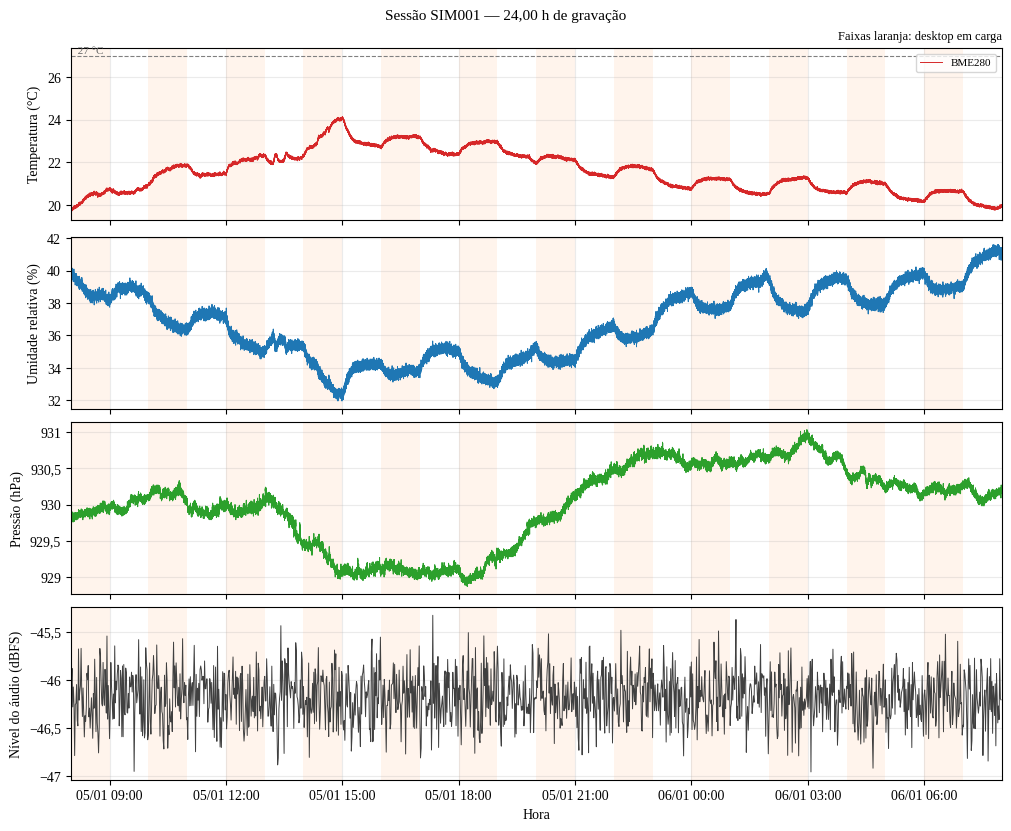

In [8]:
# 6. Figura da sessão: temperatura, umidade, pressão e nível do áudio ao longo do tempo
def eixo_x(h):
    return (T0 + pd.to_timedelta(np.asarray(h) * 3600, unit="s")) if T0 is not None else np.asarray(h)
fig, ax = plt.subplots(4, 1, figsize=(10, 8.2), sharex=True, constrained_layout=True)
ax[0].plot(eixo_x(amb.h), amb.temp, lw=0.7, color="C3", label="BME280")
ax[0].axhline(LIMITE_NORMAL, color="0.5", ls="--", lw=0.8)
ax[0].text(0.005, LIMITE_NORMAL, f" {LIMITE_NORMAL:g} °C", transform=ax[0].get_yaxis_transform(), va="bottom", fontsize=8, color="0.4")
ax[1].plot(eixo_x(amb.h), amb.umid, lw=0.7, color="C0")
ax[2].plot(eixo_x(amb.h), amb.press, lw=0.7, color="C2")
ax[3].plot(eixo_x(np.arange(len(niveis)) / 60), niveis, lw=0.7, color="0.25")
for a, r in zip(ax, ["Temperatura (°C)", "Umidade relativa (%)", "Pressão (hPa)", "Nível do áudio (dBFS)"]):
    a.set_ylabel(r); a.yaxis.set_major_formatter(virgula); a.grid(alpha=0.25)

anot = f"{PASTA}/anotacoes.csv"
if os.path.exists(anot) and T0 is not None:
    an = pd.read_csv(anot, parse_dates=["horario"])
    if ((an.horario < T0) | (an.horario > T0 + pd.to_timedelta(R["duracao_audio_h"] * 3600, unit="s"))).any():
        print("Atenção: há leituras do anotacoes.csv fora da sessão; confira o INICIO_REAL e as datas")
    ax[0].plot(an.horario, an.temp_ref, "kD", ms=4, label="Termo-higrômetro")
    if "umid_ref" in an: ax[1].plot(an.horario, an.umid_ref, "kD", ms=4)
    R["termo_higrometro_leituras"] = int(len(an))
ax[0].legend(fontsize=8, loc="upper right")

cr = f"{PASTA}/carga_repouso.csv"
fim = T0 + pd.to_timedelta(R["duracao_audio_h"] * 3600, unit="s") if T0 is not None else None
if os.path.exists(cr) and T0 is not None:
    c = pd.read_csv(cr, parse_dates=["horario"]).sort_values("horario")
    fora = ((c.horario < T0 - pd.Timedelta(minutes=5)) | (c.horario > fim)).sum()
    if fora:
        print(f"Atenção: {fora} horário(s) do carga_repouso.csv fora da sessão ({T0} a {fim}); confira o INICIO_REAL")
    for (_, a1), b in zip(c.iterrows(), list(c.horario.iloc[1:]) + [fim]):
        if str(a1.estado).strip().lower() == "carga":
            ini_f, fim_f = max(a1.horario, T0), min(b, fim)
            if ini_f < fim_f:
                for a in ax: a.axvspan(ini_f, fim_f, color="C1", alpha=0.08, lw=0)
    ax[0].set_title("Faixas laranja: desktop em carga", fontsize=9, loc="right")
for _, e in evt[evt.evento > 0].iterrows():
    for a in ax: a.axvline(eixo_x(e.amostra / FS / 3600), color="C4", lw=0.8, ls=":")
ax[3].set_xlabel("Hora" if T0 is not None else "Horas desde o início da gravação")
if T0 is not None:
    import matplotlib.dates as mdates
    ax[3].set_xlim(T0, fim)                                     # eixo sempre do início ao fim da sessão
    ax[3].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
else:
    ax[3].set_xlim(0, R["duracao_audio_h"])
fig.suptitle(f"Sessão {SESSAO} — {R['duracao_audio_h']:.2f} h de gravação".replace(".", ","), fontsize=11)
for ext in ["png", "svg"]: plt.savefig(f"{REL}/Figura_sessao_{SESSAO}.{ext}")
plt.show()

In [9]:
# 7. Resultado e relatório
R["alertas"] = alertas
R["aprovada"] = R["encerrada"] and R["amostras_perdidas"] == 0 and not (LINHA_DE_BASE and (R["eventos_marcados"] or R.get("min_acima_limite_normal", 0) > 0))
json.dump(R, open(f"{REL}/relatorio_{SESSAO}.json", "w"), indent=1, ensure_ascii=False, default=str)
print("APROVADA" if R["aprovada"] else "COM PENDÊNCIAS", "—", SESSAO)
for a in alertas: print(" •", a)
if not alertas: print(" • Nenhum alerta.")

APROVADA — SIM001
 • Nenhum alerta.


## Como interpretar

* **APROVADA**: sessão encerrada, sem perdas e, se for linha de base, sem eventos e sempre até 27 °C. Pode seguir para o notebook 09.
* **Relógio × áudio**: diferença acima de 1 s indica trecho sem gravação; anote o intervalo e não use a sessão como contínua sem declarar.
* **Lacunas no AMB.CSV**: o laço do firmware ficou parado (travas). Se a versão for 1.2-diag, confira `etapa_maior_trava`.
* **Temperatura acima de 27 °C na linha de base**: confira no termo-higrômetro (ele é a referência dos rótulos); janelas acima do limite não entram como Normal.
* **Saturação**: se aparecer, o ganho 20 é alto para o ruído do ambiente; registrar e discutir antes das sessões de eventos.